# Explainable Machine Learning-Based Phishing Website Detection and Classification
**CA-4 Use Case Based Continuous Assessment — Classification Case Study (No. 13: Phishing Detection)**

## Project Objective
Phishing websites imitate genuine sites to steal credentials and money. The objective is to **classify a website as *Phishing* or *Legitimate*** from 30 URL, HTML/JavaScript and domain-based features, and — most importantly — to **explain *why* the model flags a site**, so that a security analyst can trust, audit and act on the decision.

## Project Workflow (as required by the CA-4 document)
| Week | Activities |
|---|---|
| Week 1 | Problem understanding, dataset download, EDA (missing values, outliers, distributions, correlation), feature encoding, 70:30 split |
| Week 1 (Baseline) | Logistic Regression, Decision Tree, KNN — Accuracy, Precision, Recall, F1, Confusion Matrix, comparison table, interpretation |
| Week 2 | Random Forest, Gradient Boosting / XGBoost, GridSearchCV, cross-validation, ROC curve, AUC, class-imbalance handling (SMOTE / class weights) |
| Week 4 | **Explainability (SHAP, permutation importance, partial dependence, local explanations)**, final model justification, business insights, limitations, future improvements, optional Streamlit demo |

## Methodology
- Problem type: **Supervised binary classification** (1 = Phishing, 0 = Legitimate)
- Train-test split: **70 % train / 30 % test** (stratified)
- Metrics: **Accuracy, Precision, Recall, F1, Confusion Matrix, ROC-AUC**
- Validation: **5-fold stratified cross-validation** on the training data only
- Tuning: **GridSearchCV**; the **test set is used once** for the final evaluation
- Explainability: global (importance, SHAP summary, partial dependence) and local (per-website SHAP / contribution plot)

# WEEK 1 — Problem Understanding & Data Exploration

## 1.1 Business / scientific problem
Attackers create thousands of fake websites daily. Blacklists are always late, because a new phishing site is online for hours before it is listed. A machine-learning classifier that reads *characteristics of the site itself* (IP address in the URL, `@` symbol, URL length, HTTPS / SSL state, domain age, pop-ups, redirects, etc.) can flag **new** sites in real time.
A black-box score is hard to use in security operations, so the project adds **explainable ML**: every alert comes with the features that caused it.

* **Target variable:** `Result` (original: `-1` = phishing, `1` = legitimate) → re-coded as `Phishing` (1 = phishing, 0 = legitimate).
* **Costly mistake:** a *False Negative* (phishing site predicted legitimate) exposes users, so **Recall of the phishing class** is the key metric; Precision controls false alarms.

## 1.2 Dataset source (official)
**Phishing Websites dataset** — Kaggle: https://www.kaggle.com/datasets/anthonyjhenry/phishing-websites (based on the UCI *Phishing Websites* dataset, Mohammad, Thabtah & McCluskey).
Each feature is coded **-1 (phishing-like), 0 (suspicious) or 1 (legitimate-like)**; a few are binary (-1/1).

In [ ]:
!pip install -q xgboost shap imbalanced-learn kagglehub scipy

In [ ]:
# ---------------------------------------------------------------
# Imports, global settings and helper functions
# ---------------------------------------------------------------
import os, glob, random, textwrap, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, classification_report)
import joblib

try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except Exception:
    HAS_XGB = False
try:
    import shap
    HAS_SHAP = True
except Exception:
    HAS_SHAP = False
try:
    from imblearn.over_sampling import SMOTE
    from imblearn.pipeline import Pipeline as ImbPipeline
    HAS_SMOTE = True
except Exception:
    HAS_SMOTE = False
print("XGBoost:", HAS_XGB, "| SHAP:", HAS_SHAP, "| SMOTE (imblearn):", HAS_SMOTE)

SEED = 42
np.random.seed(SEED); random.seed(SEED)
sns.set_theme(style="whitegrid")

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=130, bbox_inches="tight")
    plt.show()

def say(text, width=110):
    print(textwrap.fill(text, width=width))

XGBoost: True | SHAP: True | SMOTE (imblearn): True


In [ ]:
# ---------------------------------------------------------------
# Locate / download the dataset
#   1) already uploaded to Colab / local folder
#   2) automatic download from Kaggle (kagglehub)
#   3) manual upload through the Colab file picker
# ---------------------------------------------------------------
TARGET_CANDIDATES = ["result", "class", "label", "status", "phishing"]

def looks_like_phishing_csv(path):
    try:
        cols = [c.lower() for c in pd.read_csv(path, nrows=1).columns]
    except Exception:
        return False
    return (any(c in TARGET_CANDIDATES for c in cols)
            and any("url_length" in c or "having_ip" in c or "sslfinal" in c for c in cols))

def find_dataset_csv():
    for folder in ["/content", "/content/data", "/data", "data", "/kaggle/input", "."]:
        for path in glob.glob(os.path.join(folder, "**", "*.csv"), recursive=True):
            if looks_like_phishing_csv(path):
                return path
    return None

DATA_FILE = find_dataset_csv()
if DATA_FILE is None:
    try:
        import kagglehub
        d = kagglehub.dataset_download("anthonyjhenry/phishing-websites")
        for path in glob.glob(os.path.join(d, "**", "*.csv"), recursive=True):
            if looks_like_phishing_csv(path):
                DATA_FILE = path; break
    except Exception as err:
        print("Automatic download was not possible:", err)
if DATA_FILE is None:
    try:
        from google.colab import files
        print("Please upload the phishing-websites CSV (from the Kaggle link above).")
        DATA_FILE = next(iter(files.upload()))
    except Exception:
        pass
if DATA_FILE is None:
    raise FileNotFoundError("Dataset not found. Download it from https://www.kaggle.com/datasets/anthonyjhenry/phishing-websites "
                            "and place the CSV next to this notebook.")
print("Dataset file:", DATA_FILE)

Automatic download was not possible: 403 Client Error.

You don't have permission to access resource at URL: https://api.kaggle.com/v1/datasets.DatasetApiService/GetDataset. Please make sure you are authenticated if you are trying to access a private resource or a resource requiring consent.
Please upload the phishing-websites CSV (from the Kaggle link above).


Saving phishing+websites.zip to phishing+websites (1).zip
Dataset file: phishing+websites (1).zip


In [ ]:
import zipfile
from scipy.io import arff

# Extract the specific ARFF data file from the ZIP file
with zipfile.ZipFile(DATA_FILE, 'r') as z:
    # Find the training dataset file in the zip archive
    arff_file_name = next(name for name in z.namelist() if name.endswith('.arff') and 'training' in name.lower())
    z.extract(arff_file_name, '.')

# Load the ARFF file using scipy and convert to a pandas DataFrame
arff_data, arff_meta = arff.loadarff(arff_file_name)
data = pd.DataFrame(arff_data)

# Convert bytes columns to strings/numbers if needed
for col in data.columns:
    if data[col].dtype == object:
        data[col] = data[col].str.decode('utf-8').astype(int)

# drop index / id columns if present, tidy column names
data = data.drop(columns=[c for c in data.columns if c.lower().startswith("unnamed") or c.lower() in ("id", "index")], errors="ignore")
data.columns = [c.strip() for c in data.columns]

# identify the target column and re-code: original -1 = phishing, 1 = legitimate  ->  Phishing: 1 / 0
target_col = next(c for c in data.columns if c.lower() in TARGET_CANDIDATES)
raw = data[target_col]
if set(raw.unique()) <= {-1, 1}:
    data["Phishing"] = (raw == -1).astype(int)
elif set(raw.unique()) <= {0, 1}:
    data["Phishing"] = raw.astype(int)
else:
    data["Phishing"] = (raw.astype(str).str.lower().isin(["phishing", "bad", "malicious"])).astype(int)
if target_col != "Phishing":
    data = data.drop(columns=[target_col])

print("DATASET LOADED SUCCESSFULLY!  Shape:", data.shape)
display(data.head())
data.info()

DATASET LOADED SUCCESSFULLY!  Shape: (11055, 31)


,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Phishing
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,-1,-1,-1,-1,1,1,-1,1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,-1,-1,0,-1,1,1,1,1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,-1,1,-1,1,0,-1,1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,-1,-1,1,-1,1,-1,1,1
4,1,0,-1,1,1,-1,1,1,-1,1,...,-1,1,-1,-1,0,-1,1,1,1,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11055 entries, 0 to 11054
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   having_IP_Address            11055 non-null  int64
 1   URL_Length                   11055 non-null  int64
 2   Shortining_Service           11055 non-null  int64
 3   having_At_Symbol             11055 non-null  int64
 4   double_slash_redirecting     11055 non-null  int64
 5   Prefix_Suffix                11055 non-null  int64
 6   having_Sub_Domain            11055 non-null  int64
 7   SSLfinal_State               11055 non-null  int64
 8   Domain_registeration_length  11055 non-null  int64
 9   Favicon                      11055 non-null  int64
 10  port                         11055 non-null  int64
 11  HTTPS_token                  11055 non-null  int64
 12  Request_URL                  11055 non-null  int64
 13  URL_of_Anchor                11055 non-null  i

## 1.3 Dataset description — size, feature types and target variable

Rows    : 11055
Columns : 31 (30 features + target)


,Feature,Data type,Distinct values,Feature type
0,having_IP_Address,int64,"[-1, 1]",Binary (-1/1)
1,URL_Length,int64,"[-1, 0, 1]",Ternary categorical (-1/0/1)
2,Shortining_Service,int64,"[-1, 1]",Binary (-1/1)
3,having_At_Symbol,int64,"[-1, 1]",Binary (-1/1)
4,double_slash_redirecting,int64,"[-1, 1]",Binary (-1/1)
5,Prefix_Suffix,int64,"[-1, 1]",Binary (-1/1)
6,having_Sub_Domain,int64,"[-1, 0, 1]",Ternary categorical (-1/0/1)
7,SSLfinal_State,int64,"[-1, 0, 1]",Ternary categorical (-1/0/1)
8,Domain_registeration_length,int64,"[-1, 1]",Binary (-1/1)
9,Favicon,int64,"[-1, 1]",Binary (-1/1)


TARGET VARIABLE: Phishing (1 = phishing, 0 = legitimate)


,Count,Percent
Phishing,,
0,6157,55.69
1,4898,44.31


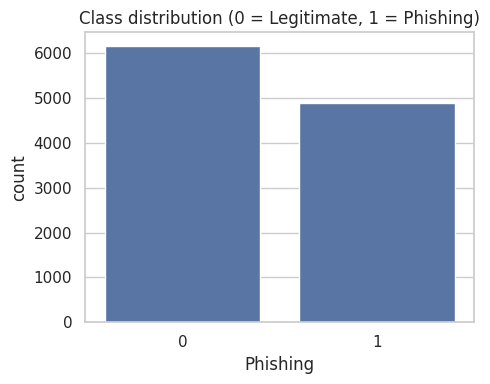

In [ ]:
print("Rows    :", data.shape[0])
print("Columns :", data.shape[1], "(30 features + target)" if data.shape[1] == 31 else "")

features = [c for c in data.columns if c != "Phishing"]
levels = {c: sorted(data[c].unique().tolist()) for c in features}
feature_types = pd.DataFrame({
    "Feature": features,
    "Data type": [str(data[c].dtype) for c in features],
    "Distinct values": [levels[c] for c in features],
    "Feature type": ["Ternary categorical (-1/0/1)" if len(levels[c]) == 3 else "Binary (-1/1)" if len(levels[c]) == 2 else "Other" for c in features],
})
display(feature_types)

print("TARGET VARIABLE: Phishing (1 = phishing, 0 = legitimate)")
tc = data["Phishing"].value_counts().to_frame("Count")
tc["Percent"] = (100 * tc["Count"] / len(data)).round(2)
display(tc)
plt.figure(figsize=(5, 4)); sns.countplot(x="Phishing", data=data); plt.title("Class distribution (0 = Legitimate, 1 = Phishing)"); save_fig("01_class_balance")

**Feature-type explanation.** All features are *pre-encoded* categorical indicators: `-1` = phishing-like, `0` = suspicious, `1` = legitimate-like (e.g. `having_IP_Address`, `Prefix_Suffix`, `SSLfinal_State`, `URL_of_Anchor`, `web_traffic`, `Request_URL`). There are no free-text or date columns. Feature groups: **URL-based**, **HTML/JavaScript-based**, **domain-based**.
**Leakage check:** every feature is measured from the website itself *before* any label exists, so none leaks the target.

In [ ]:
# Missing values and duplicates
missing = pd.DataFrame({"Missing values": data.isnull().sum(), "Missing %": (data.isnull().mean() * 100).round(3)})
display(missing[missing["Missing values"] > 0] if missing["Missing values"].sum() else missing.head(3))
print("Total missing values:", int(data.isnull().sum().sum()))

dups = data.duplicated().sum()
print("Duplicate rows:", dups)
# Duplicates are common in this dataset (many sites share the same coded profile). They are removed so that identical rows
# cannot appear in BOTH train and test and inflate the scores.
data = data.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", data.shape)

if data.isnull().sum().sum() > 0:
    data = data.fillna(data.mode().iloc[0])
    print("Missing values imputed with the column mode (categorical features).")
else:
    print("No missing values -> no imputation required.")

,Missing values,Missing %
having_IP_Address,0,0.0
URL_Length,0,0.0
Shortining_Service,0,0.0


Total missing values: 0
Duplicate rows: 5206
Shape after removing duplicates: (5849, 31)
No missing values -> no imputation required.


**Missing-value interpretation.** The dataset is complete (no missing values), so no imputation is needed. Duplicate rows (if any) were removed to avoid train/test leakage.

## 1.4 Distribution analysis

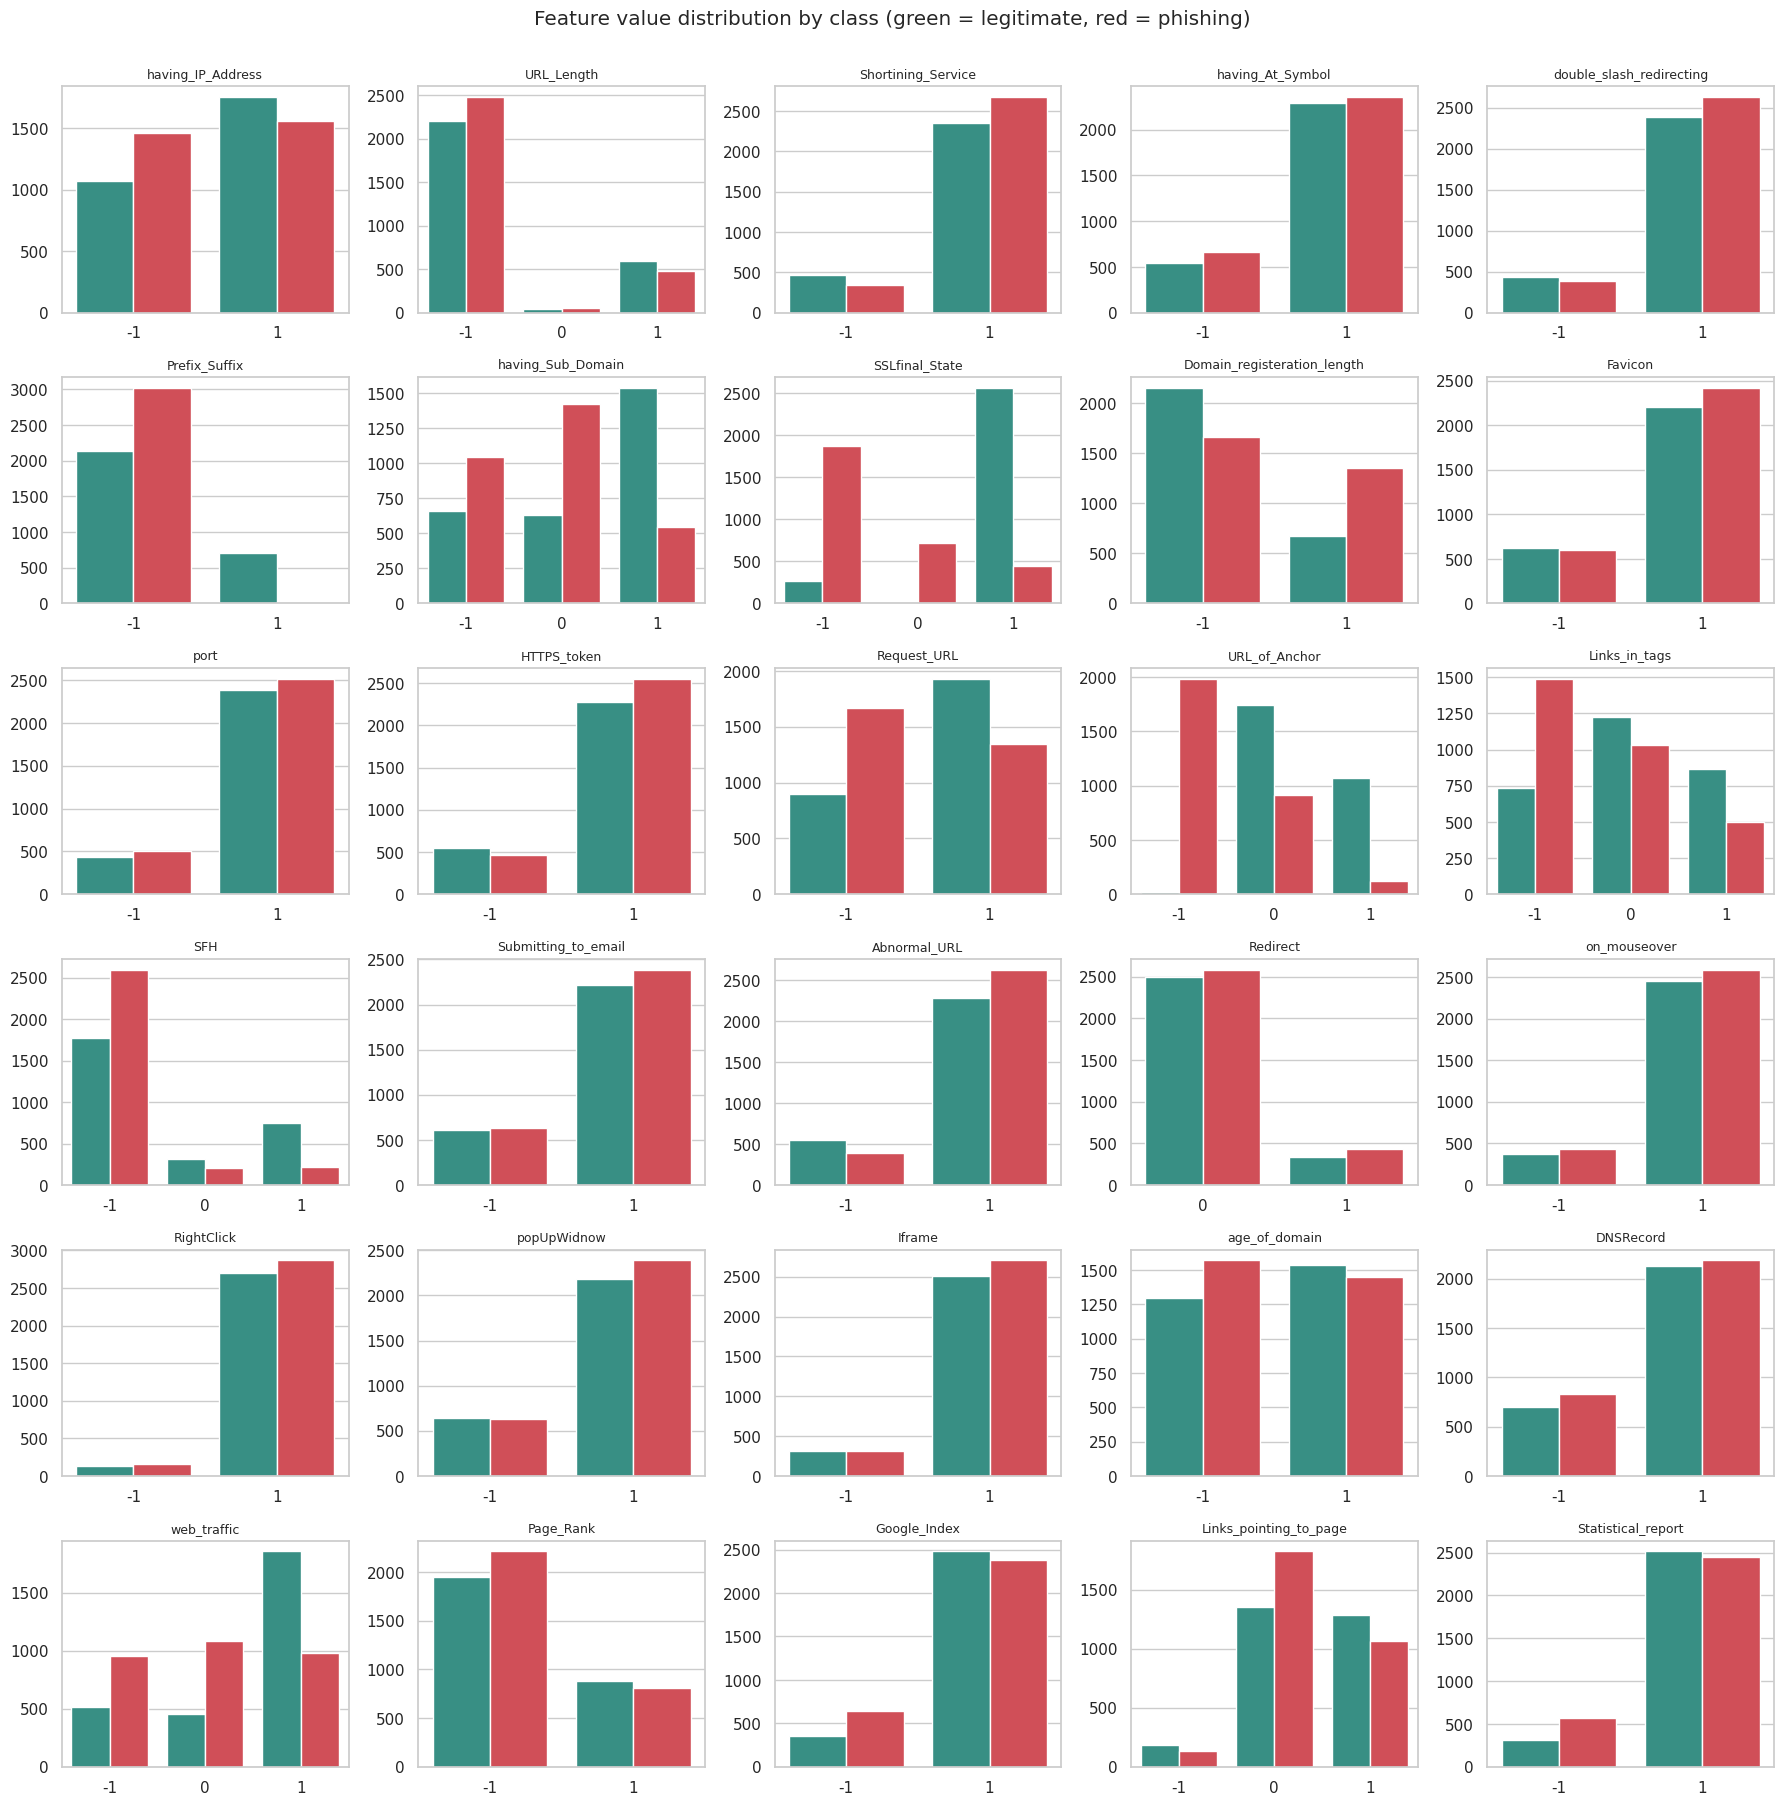

,P(phishing | value=-1),P(phishing | value=1),P(phishing | value=0)
URL_of_Anchor,0.991,0.104,0.344
SSLfinal_State,0.876,0.147,0.990
Links_in_tags,0.670,0.365,0.457
Request_URL,0.650,0.411,NaN
web_traffic,0.649,0.345,0.705
Google_Index,0.647,0.490,NaN
Statistical_report,0.644,0.493,NaN
having_Sub_Domain,0.614,0.263,0.692
SFH,0.594,0.223,0.402
Prefix_Suffix,0.586,0.000,NaN


In [ ]:
n = len(features); ncols = 5; nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 3 * nrows))
for ax, col in zip(axes.ravel(), features):
    sns.countplot(x=col, hue="Phishing", data=data, ax=ax, palette=["#2a9d8f", "#e63946"], legend=False)
    ax.set_title(col, fontsize=9); ax.set_xlabel(""); ax.set_ylabel("")
for ax in axes.ravel()[n:]: ax.axis("off")
plt.suptitle("Feature value distribution by class (green = legitimate, red = phishing)", y=1.002)
save_fig("02_feature_distributions")

# Phishing rate for each feature value (-1 / 0 / 1) -> a first, simple explanation of the data
rate = {c: data.groupby(c)["Phishing"].mean().round(3).to_dict() for c in features}
rate_table = pd.DataFrame(rate).T
rate_table.columns = [f"P(phishing | value={c})" for c in rate_table.columns]
display(rate_table.sort_values(rate_table.columns[0], ascending=False))

In [ ]:
dist = pd.DataFrame({"Skewness": data[features].skew().round(3), "Most frequent value share %": [round(100 * data[c].value_counts(normalize=True).iloc[0], 1) for c in features]})
display(dist.sort_values("Skewness", key=abs, ascending=False).head(10))
say("Interpretation (distributions): each feature takes only 2-3 coded values, so skewness mainly shows how one-sided a feature is. "
    "Features where the red (phishing) and green (legitimate) bars differ strongly between values (for example SSLfinal_State, URL_of_Anchor, "
    "web_traffic, Prefix_Suffix) separate the classes well; features whose bars look alike carry little signal.")

,Skewness,Most frequent value share %
RightClick,-4.176,95.1
Iframe,-2.540,89.3
Prefix_Suffix,2.342,88.0
Redirect,2.177,86.8
on_mouseover,-2.094,86.2
Shortining_Service,-2.077,86.0
double_slash_redirecting,-2.065,85.9
Statistical_report,-1.945,84.9
Abnormal_URL,-1.846,83.9
port,-1.843,83.9


Interpretation (distributions): each feature takes only 2-3 coded values, so skewness mainly shows how one-
sided a feature is. Features where the red (phishing) and green (legitimate) bars differ strongly between
values (for example SSLfinal_State, URL_of_Anchor, web_traffic, Prefix_Suffix) separate the classes well;
features whose bars look alike carry little signal.


## 1.5 Outlier detection

Features with codes outside {-1, 0, 1}: none


,Feature,Value,Share %
0,URL_Length,0,1.64
1,RightClick,-1,4.91


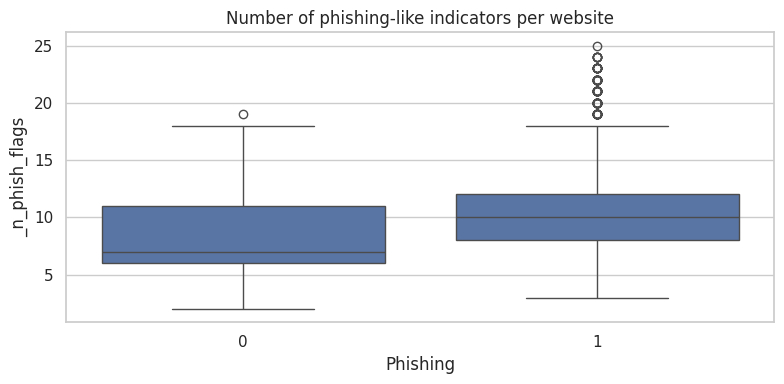

In [ ]:
# Features are coded categories (-1/0/1), so classical numeric outliers (IQR / Z-score) do not exist: every value is a valid code.
# We verify this, and look for *rare categories* and for impossible codes.
valid = {-1, 0, 1}
bad_codes = {c: sorted(set(data[c].unique()) - valid) for c in features if set(data[c].unique()) - valid}
print("Features with codes outside {-1, 0, 1}:", bad_codes if bad_codes else "none")

rare = []
for c in features:
    vc = data[c].value_counts(normalize=True)
    for v, p in vc.items():
        if p < 0.05: rare.append({"Feature": c, "Value": v, "Share %": round(100 * p, 2)})
display(pd.DataFrame(rare).sort_values("Share %") if rare else "No rare categories (<5%)")

# Also check for rows that are 'extreme' in the sense of having an unusually large number of phishing-like indicators
data["_n_phish_flags"] = (data[features] == -1).sum(axis=1)
plt.figure(figsize=(8, 4)); sns.boxplot(x="Phishing", y="_n_phish_flags", data=data); plt.title("Number of phishing-like indicators per website"); save_fig("03_flags_boxplot")
data = data.drop(columns="_n_phish_flags")

**Outlier interpretation.** Because every feature is a coded indicator, there are no numeric outliers to remove. Rare categories are genuine information (e.g. an unusual URL trick) and are **kept**. The box-plot shows that phishing sites typically trigger more phishing-like indicators.

## 1.6 Correlation analysis

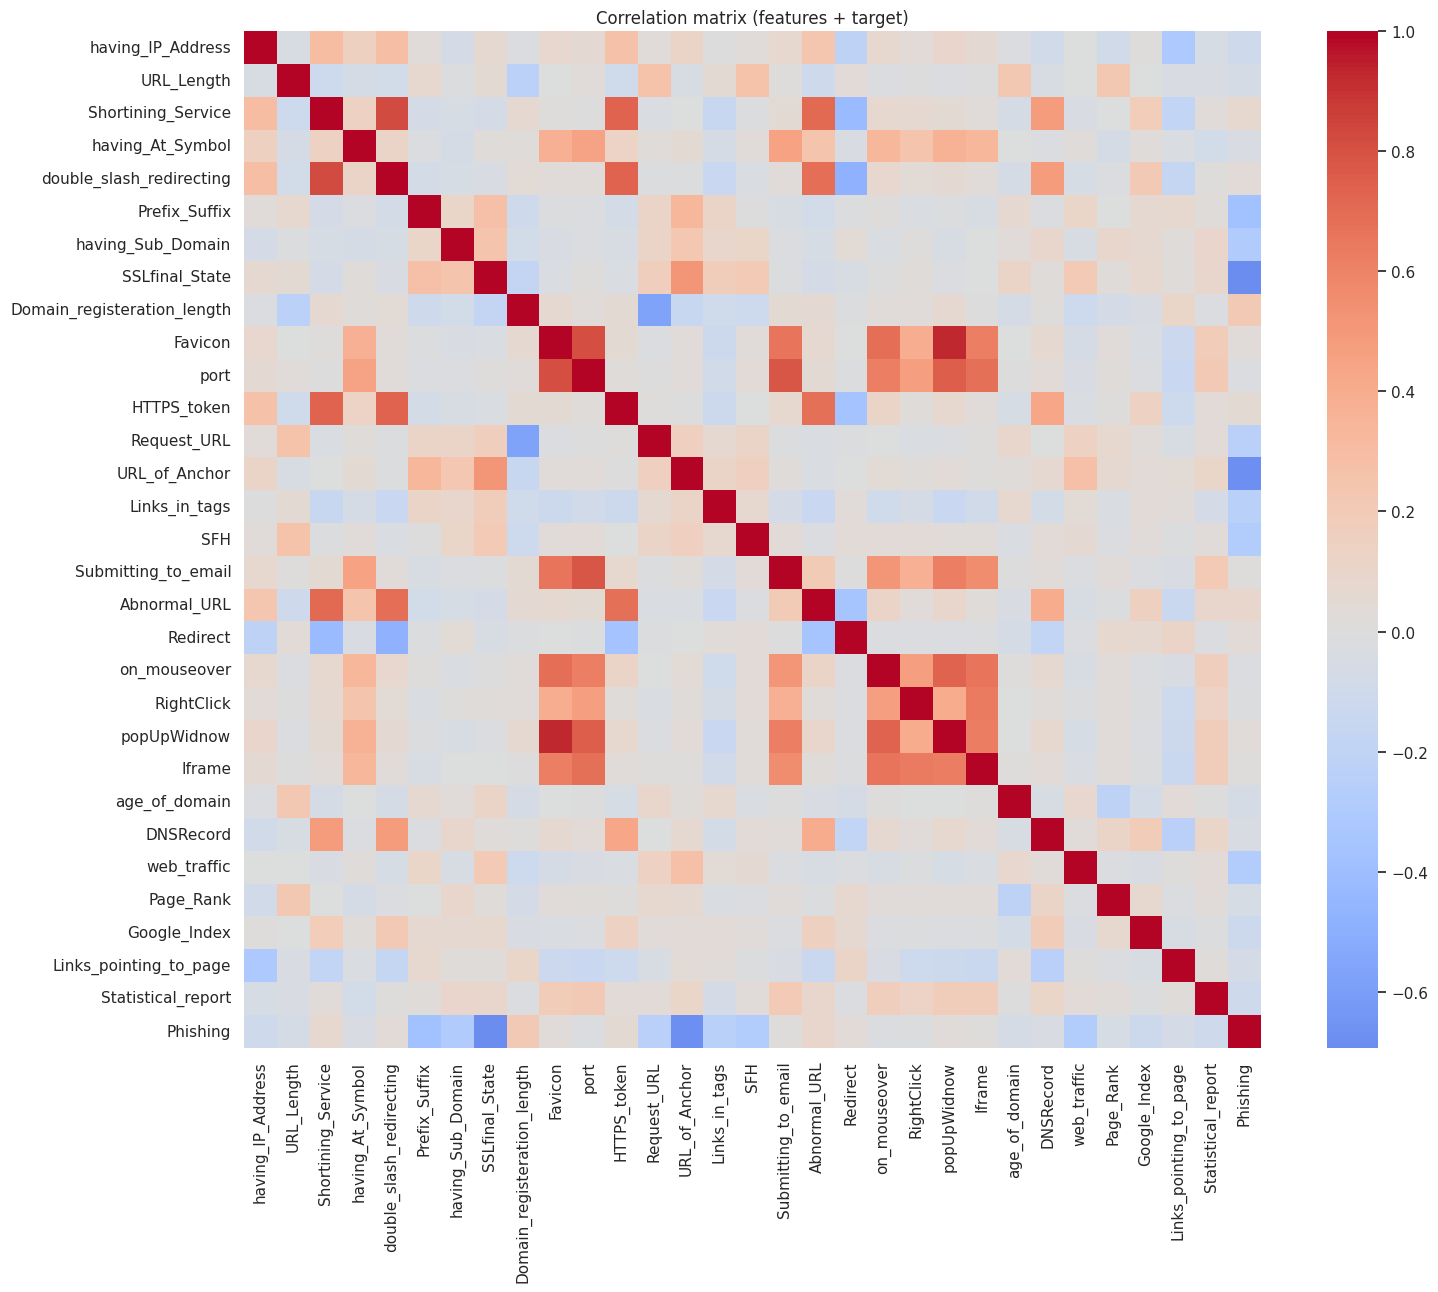

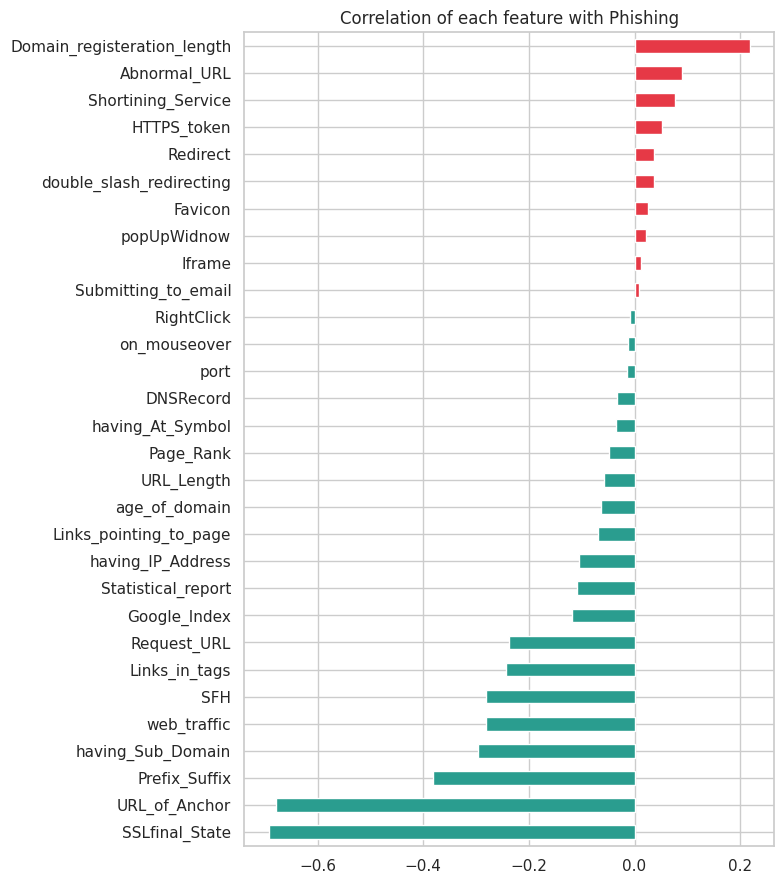

,Correlation with Phishing
SSLfinal_State,-0.693228
URL_of_Anchor,-0.679125
Prefix_Suffix,-0.381134
having_Sub_Domain,-0.296214
web_traffic,-0.281709
SFH,-0.281131
Links_in_tags,-0.243864
Request_URL,-0.237778
Domain_registeration_length,0.218623
Google_Index,-0.118217


|corr|
Favicon                  popUpWidnow               0.933145
Shortining_Service       double_slash_redirecting  0.815809
Favicon                  port                      0.812657
port                     Submitting_to_email       0.784856
                         popUpWidnow               0.754950
double_slash_redirecting HTTPS_token               0.736728
on_mouseover             popUpWidnow               0.731814
Shortining_Service       HTTPS_token               0.729916

,VIF
Favicon,10.04
popUpWidnow,8.94
port,5.21
double_slash_redirecting,4.09
Shortining_Service,3.93
Submitting_to_email,3.07
Iframe,2.90
Abnormal_URL,2.80


In [ ]:
corr = data.corr()
plt.figure(figsize=(16, 13)); sns.heatmap(corr, cmap="coolwarm", center=0, annot=False, square=True); plt.title("Correlation matrix (features + target)"); save_fig("04_correlation_heatmap")

target_corr = corr["Phishing"].drop("Phishing").sort_values()
plt.figure(figsize=(8, 9)); target_corr.plot(kind="barh", color=np.where(target_corr > 0, "#e63946", "#2a9d8f")); plt.title("Correlation of each feature with Phishing"); save_fig("05_target_correlation")
display(target_corr.to_frame("Correlation with Phishing").sort_values("Correlation with Phishing", key=abs, ascending=False).head(10))

# Multicollinearity: highly correlated feature pairs and VIF (plain numpy)
pairs = (corr.drop(index="Phishing", columns="Phishing").abs().where(np.triu(np.ones((len(features), len(features))), k=1).astype(bool)).stack().sort_values(ascending=False))
display(pairs.head(8).to_frame("|corr|"))
Xc = data[features].values.astype(float); Xc = (Xc - Xc.mean(0)) / (Xc.std(0) + 1e-9)
vif = np.diag(np.linalg.pinv(np.corrcoef(Xc, rowvar=False)))
display(pd.Series(vif, index=features).sort_values(ascending=False).head(8).round(2).to_frame("VIF"))

In [ ]:
top = target_corr.abs().sort_values(ascending=False)
say(f"Interpretation (correlation): the features most correlated with phishing are {', '.join(top.index[:3])} "
    f"(|r| = {top.iloc[0]:.2f}, {top.iloc[1]:.2f}, {top.iloc[2]:.2f}). Negative correlation means that the legitimate-like code (+1) goes with legitimate sites. "
    f"Several URL/HTML features are moderately correlated with each other, which is typical for this dataset; tree ensembles handle this well, "
    f"and it is the reason why SHAP / permutation importance (not only coefficients) are used for explanation in Week 4.")

Interpretation (correlation): the features most correlated with phishing are SSLfinal_State, URL_of_Anchor,
Prefix_Suffix (|r| = 0.69, 0.68, 0.38). Negative correlation means that the legitimate-like code (+1) goes
with legitimate sites. Several URL/HTML features are moderately correlated with each other, which is typical
for this dataset; tree ensembles handle this well, and it is the reason why SHAP / permutation importance (not
only coefficients) are used for explanation in Week 4.


## 1.7 Feature encoding

In [ ]:
# All features are already numerically encoded (-1, 0, 1). They are ORDINAL-like indicators (phishing -> suspicious -> legitimate),
# so no one-hot encoding is needed and keeping them as numbers keeps the model explainable (one column = one website property).
obj_cols = [c for c in features if data[c].dtype == "object"]
print("Object (text) columns needing encoding:", obj_cols if obj_cols else "none")
X = data[features].astype(int)
y = data["Phishing"].astype(int)
print("X shape:", X.shape, "| y shape:", y.shape)

Object (text) columns needing encoding: none
X shape: (5849, 30) | y shape: (5849,)


## 1.8 Train-test split (70 : 30)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=SEED, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)
print(pd.DataFrame({"Train %": y_train.value_counts(normalize=True) * 100, "Test %": y_test.value_counts(normalize=True) * 100}).round(2))
IMBALANCE_RATIO = y_train.value_counts().max() / y_train.value_counts().min()
print(f"Class imbalance ratio (majority/minority): {IMBALANCE_RATIO:.2f}")

Train: (4094, 30)  Test: (1755, 30)
          Train %  Test %
Phishing                 
1           51.61   51.62
0           48.39   48.38
Class imbalance ratio (majority/minority): 1.07


Stratified splitting keeps the phishing / legitimate proportion identical in train and test. The class ratio is checked here and handled explicitly in Week 2 (class weights and SMOTE).

# WEEK 1 — Baseline Modeling (Classification)

In [ ]:
results, predictions, probabilities, models = {}, {}, {}, {}

def evaluate_model(name, model, verbose=True):
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else None
    results[name] = {"Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred),
                     "Recall": recall_score(y_test, pred), "F1 Score": f1_score(y_test, pred),
                     "ROC-AUC": roc_auc_score(y_test, proba) if proba is not None else np.nan}
    predictions[name], probabilities[name], models[name] = pred, proba, model
    if verbose:
        print(f"--- {name} ---"); print(pd.Series(results[name]).round(4).to_string())

def results_table(): return pd.DataFrame(results).T.reset_index().rename(columns={"index": "Model"}).sort_values("F1 Score", ascending=False).reset_index(drop=True)

lr  = Pipeline([("scaler", StandardScaler()), ("model", LogisticRegression(max_iter=2000, random_state=SEED))]).fit(X_train, y_train)
dt  = DecisionTreeClassifier(random_state=SEED).fit(X_train, y_train)
knn = Pipeline([("scaler", StandardScaler()), ("model", KNeighborsClassifier())]).fit(X_train, y_train)
evaluate_model("Logistic Regression", lr); evaluate_model("Decision Tree", dt); evaluate_model("KNN", knn)

baseline_results = results_table()
print("\nBASELINE MODEL COMPARISON"); display(baseline_results.style.format({c: "{:.4f}" for c in baseline_results.columns if c != "Model"}))

--- Logistic Regression ---
Accuracy     0.9071
Precision    0.9132
Recall       0.9062
F1 Score     0.9097
ROC-AUC      0.9728
--- Decision Tree ---
Accuracy     0.9031
Precision    0.9220
Recall       0.8874
F1 Score     0.9044
ROC-AUC      0.9103
--- KNN ---
Accuracy     0.9060
Precision    0.9014
Recall       0.9183
F1 Score     0.9098
ROC-AUC      0.9666

BASELINE MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,KNN,0.9060,0.9014,0.9183,0.9098,0.9666
1,Logistic Regression,0.9071,0.9132,0.9062,0.9097,0.9728
2,Decision Tree,0.9031,0.9220,0.8874,0.9044,0.9103


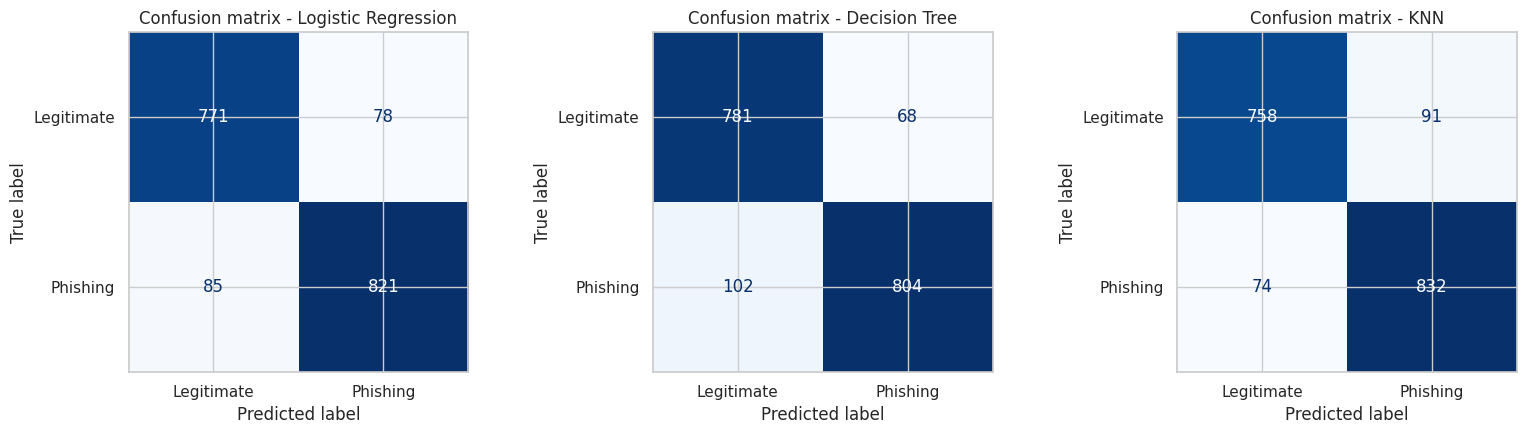

Interpretation (baselines): KNN gives the best F1 (0.910) with accuracy 0.906, precision 0.901 and recall
0.918. Its confusion matrix has 74 phishing sites missed (false negatives - the dangerous error) and 91
legitimate sites wrongly flagged (false positives - the annoying error). Logistic Regression is a transparent
linear reference; the unpruned Decision Tree tends to over-fit; KNN depends on distance in a space of coded
indicators. These baselines are improved with ensembles and tuning in Week 2.


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, name in zip(axes, ["Logistic Regression", "Decision Tree", "KNN"]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, predictions[name]), display_labels=["Legitimate", "Phishing"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"Confusion matrix - {name}")
save_fig("06_baseline_confusion")

best_b = baseline_results.iloc[0]
tn, fp, fn, tp = confusion_matrix(y_test, predictions[best_b["Model"]]).ravel()
say(f"Interpretation (baselines): {best_b['Model']} gives the best F1 ({best_b['F1 Score']:.3f}) with accuracy {best_b['Accuracy']:.3f}, "
    f"precision {best_b['Precision']:.3f} and recall {best_b['Recall']:.3f}. Its confusion matrix has {fn} phishing sites missed (false negatives - the dangerous error) "
    f"and {fp} legitimate sites wrongly flagged (false positives - the annoying error). Logistic Regression is a transparent linear reference; the unpruned Decision Tree "
    f"tends to over-fit; KNN depends on distance in a space of coded indicators. These baselines are improved with ensembles and tuning in Week 2.")

# WEEK 2 — Advanced Modeling & Optimization

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
tuning_summary = []

def tune(name, estimator, grid, key):
    g = GridSearchCV(estimator, grid, cv=cv, scoring="f1", n_jobs=-1).fit(X_train, y_train)
    tuning_summary.append({"Model": name, "Method": "GridSearchCV", "Best parameters": str(g.best_params_), "CV F1": g.best_score_})
    evaluate_model(name, g.best_estimator_, verbose=False)
    return g.best_estimator_

# class_weight="balanced" is used inside the models -> handles class imbalance without changing the data
best_rf = tune("Tuned Random Forest", RandomForestClassifier(random_state=SEED, class_weight="balanced", n_jobs=-1),
               {"n_estimators": [200, 400], "max_depth": [None, 15, 25], "min_samples_leaf": [1, 2]}, "rf")
best_gb = tune("Tuned Gradient Boosting", GradientBoostingClassifier(random_state=SEED),
               {"n_estimators": [150, 300], "learning_rate": [0.05, 0.1], "max_depth": [3, 5]}, "gb")
if HAS_XGB:
    best_xgb = tune("Tuned XGBoost", XGBClassifier(random_state=SEED, eval_metric="logloss", n_jobs=1),
                    {"n_estimators": [200, 400], "learning_rate": [0.05, 0.1], "max_depth": [4, 6], "subsample": [0.8, 1.0]}, "xgb")
else:
    best_xgb = tune("Tuned XGBoost", HistGradientBoostingClassifier(random_state=SEED),
                    {"max_iter": [200, 400], "learning_rate": [0.05, 0.1], "max_depth": [None, 6]}, "xgb")
    print("XGBoost not installed -> HistGradientBoosting used as the XGBoost-style model.")
best_lr  = tune("Tuned Logistic Regression", Pipeline([("scaler", StandardScaler()), ("model", LogisticRegression(max_iter=3000, class_weight="balanced", random_state=SEED))]),
                {"model__C": [0.01, 0.1, 1, 10, 100]}, "lr")
best_dt  = tune("Tuned Decision Tree", DecisionTreeClassifier(random_state=SEED, class_weight="balanced"),
                {"max_depth": [4, 6, 8, 12, None], "min_samples_leaf": [1, 5, 10], "criterion": ["gini", "entropy"]}, "dt")
best_knn = tune("Tuned KNN", Pipeline([("scaler", StandardScaler()), ("model", KNeighborsClassifier())]),
                {"model__n_neighbors": [3, 5, 7, 11, 15], "model__weights": ["uniform", "distance"], "model__p": [1, 2]}, "knn")

print("HYPER-PARAMETER TUNING SUMMARY")
tuning_table = pd.DataFrame(tuning_summary).sort_values("CV F1", ascending=False).reset_index(drop=True)
display(tuning_table)

HYPER-PARAMETER TUNING SUMMARY


,Model,Method,Best parameters,CV F1
0,Tuned XGBoost,GridSearchCV,"{'learning_rate': 0.1, 'max_depth': 4, 'n_esti...",0.952738
1,Tuned Gradient Boosting,GridSearchCV,"{'learning_rate': 0.1, 'max_depth': 5, 'n_esti...",0.951762
2,Tuned Random Forest,GridSearchCV,"{'max_depth': None, 'min_samples_leaf': 2, 'n_...",0.949430
3,Tuned KNN,GridSearchCV,"{'model__n_neighbors': 15, 'model__p': 1, 'mod...",0.936140
4,Tuned Decision Tree,GridSearchCV,"{'criterion': 'entropy', 'max_depth': 12, 'min...",0.930255
5,Tuned Logistic Regression,GridSearchCV,{'model__C': 0.1},0.925966


GridSearchCV tries every parameter combination with 5-fold stratified cross-validation and keeps the combination with the best **F1**. Tuning uses the training data only, so the test set stays untouched.

### Class-imbalance handling (class weights and SMOTE)

In [ ]:
print(f"Imbalance ratio = {IMBALANCE_RATIO:.2f}  ->  ", "mild imbalance" if IMBALANCE_RATIO < 1.5 else "noticeable imbalance")
rows = []
rf_params = dict(n_estimators=300, random_state=SEED, n_jobs=-1)
variants = {"RF - no handling": RandomForestClassifier(**rf_params),
            "RF - class_weight=balanced": RandomForestClassifier(class_weight="balanced", **rf_params)}
if HAS_SMOTE:
    # SMOTE sits INSIDE the pipeline, so synthetic samples are created only from the training folds (no leakage into validation folds)
    variants["RF - SMOTE"] = ImbPipeline([("smote", SMOTE(random_state=SEED)), ("model", RandomForestClassifier(**rf_params))])
else:
    print("imbalanced-learn not installed -> SMOTE skipped (class weights used).")
for name, est in variants.items():
    s = cross_validate(est, X_train, y_train, cv=cv, scoring={"f1": "f1", "recall": "recall", "precision": "precision"}, n_jobs=1)
    rows.append({"Strategy": name, "CV Precision": s["test_precision"].mean(), "CV Recall": s["test_recall"].mean(), "CV F1": s["test_f1"].mean()})
imb_table = pd.DataFrame(rows).sort_values("CV F1", ascending=False).reset_index(drop=True)
display(imb_table.style.format({c: "{:.4f}" for c in imb_table.columns if c != "Strategy"}))
say("Interpretation (imbalance): the dataset is only mildly imbalanced, so all strategies score very similarly. Class weights are kept in the final models because they "
    "give the same benefit as SMOTE without creating artificial websites, which keeps the explanations faithful to real data.")

Imbalance ratio = 1.07  ->   mild imbalance


,Strategy,CV Precision,CV Recall,CV F1
0,RF - SMOTE,0.9568,0.9413,0.9490
1,RF - class_weight=balanced,0.9542,0.9437,0.9489
2,RF - no handling,0.9537,0.9427,0.9481


Interpretation (imbalance): the dataset is only mildly imbalanced, so all strategies score very similarly.
Class weights are kept in the final models because they give the same benefit as SMOTE without creating
artificial websites, which keeps the explanations faithful to real data.


### Cross-validation of all models

,Model,CV Accuracy,CV Precision,CV Recall,CV F1 (mean),CV F1 (std),CV AUC
0,Tuned XGBoost,0.9514,0.9567,0.9489,0.9527,0.0081,0.9918
1,Tuned Gradient Boosting,0.9504,0.9557,0.9479,0.9518,0.0054,0.9920
2,Tuned Random Forest,0.9482,0.9572,0.9418,0.9494,0.0042,0.9898
3,Tuned KNN,0.9343,0.9395,0.9328,0.9361,0.0064,0.9686
4,Tuned Decision Tree,0.9284,0.9359,0.9248,0.9303,0.0050,0.9527
5,Tuned Logistic Regression,0.9243,0.9346,0.9176,0.9260,0.0065,0.9769
6,Logistic Regression,0.9233,0.9308,0.9200,0.9253,0.0061,0.9770
7,Decision Tree,0.9189,0.9215,0.9214,0.9214,0.0048,0.9211
8,KNN,0.9140,0.9122,0.9224,0.9172,0.0095,0.9733


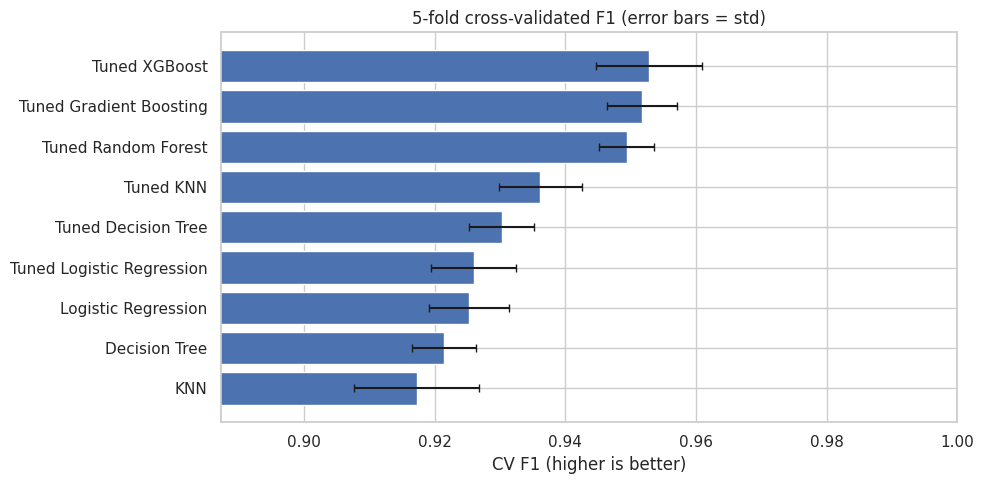

Interpretation (cross-validation): Tuned XGBoost has the best average validation F1 (0.9527) with CV AUC
0.9918. A small standard deviation means the result does not depend on one particular subset of the data.


In [ ]:
cv_models = {"Logistic Regression": models["Logistic Regression"], "Decision Tree": models["Decision Tree"], "KNN": models["KNN"],
             "Tuned Logistic Regression": models["Tuned Logistic Regression"], "Tuned Decision Tree": models["Tuned Decision Tree"],
             "Tuned KNN": models["Tuned KNN"], "Tuned Random Forest": models["Tuned Random Forest"],
             "Tuned Gradient Boosting": models["Tuned Gradient Boosting"], "Tuned XGBoost": models["Tuned XGBoost"]}
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}
cv_rows, cv_f1 = [], {}
for name, est in cv_models.items():
    s = cross_validate(est, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    cv_f1[name] = s["test_f1"].mean()
    cv_rows.append({"Model": name, "CV Accuracy": s["test_accuracy"].mean(), "CV Precision": s["test_precision"].mean(), "CV Recall": s["test_recall"].mean(),
                    "CV F1 (mean)": s["test_f1"].mean(), "CV F1 (std)": s["test_f1"].std(), "CV AUC": s["test_roc_auc"].mean()})
cv_table = pd.DataFrame(cv_rows).sort_values("CV F1 (mean)", ascending=False).reset_index(drop=True)
display(cv_table.style.format({c: "{:.4f}" for c in cv_table.columns if c != "Model"}))
plt.figure(figsize=(10, 5)); plt.barh(cv_table["Model"][::-1], cv_table["CV F1 (mean)"][::-1], xerr=cv_table["CV F1 (std)"][::-1], capsize=3)
plt.xlim(max(0.8, cv_table["CV F1 (mean)"].min() - 0.03), 1.0); plt.xlabel("CV F1 (higher is better)"); plt.title("5-fold cross-validated F1 (error bars = std)"); save_fig("07_cv_f1")
say(f"Interpretation (cross-validation): {cv_table.iloc[0]['Model']} has the best average validation F1 ({cv_table.iloc[0]['CV F1 (mean)']:.4f}) with CV AUC {cv_table.iloc[0]['CV AUC']:.4f}. "
    f"A small standard deviation means the result does not depend on one particular subset of the data.")

### Final model comparison, ROC curve and AUC

FINAL MODEL COMPARISON (same test set; CV F1 = validation on the training data)


,Rank,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,CV F1
0,1,Tuned Gradient Boosting,0.9487,0.9554,0.9448,0.9501,0.9924,0.9518
1,2,Tuned XGBoost,0.9436,0.9539,0.9360,0.9448,0.9912,0.9527
2,3,Tuned Random Forest,0.9316,0.9466,0.9194,0.9328,0.9871,0.9494
3,4,Tuned Decision Tree,0.9254,0.9398,0.9139,0.9267,0.9618,0.9303
4,5,Tuned KNN,0.9214,0.9267,0.9205,0.9236,0.9585,0.9361
5,6,Tuned Logistic Regression,0.9088,0.9200,0.9018,0.9108,0.9725,0.9260
6,7,KNN,0.9060,0.9014,0.9183,0.9098,0.9666,0.9172
7,8,Logistic Regression,0.9071,0.9132,0.9062,0.9097,0.9728,0.9253
8,9,Decision Tree,0.9031,0.9220,0.8874,0.9044,0.9103,0.9214


SELECTED MODEL (highest cross-validated F1): Tuned XGBoost


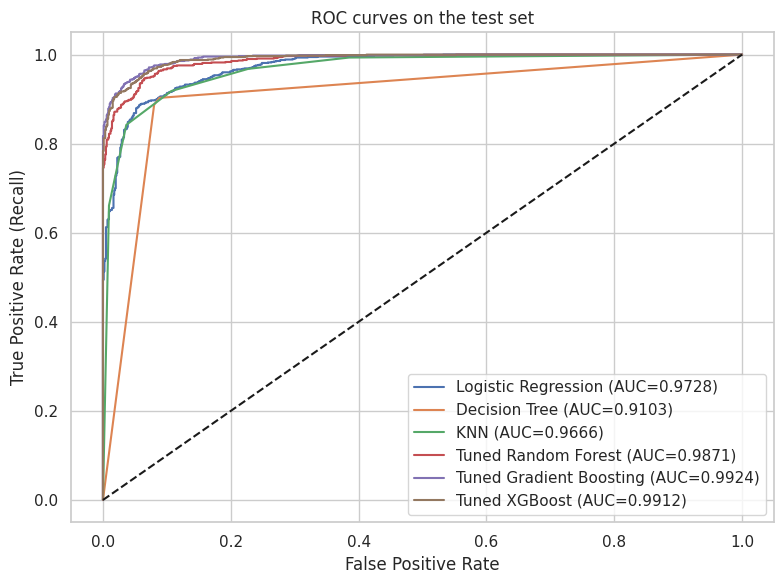

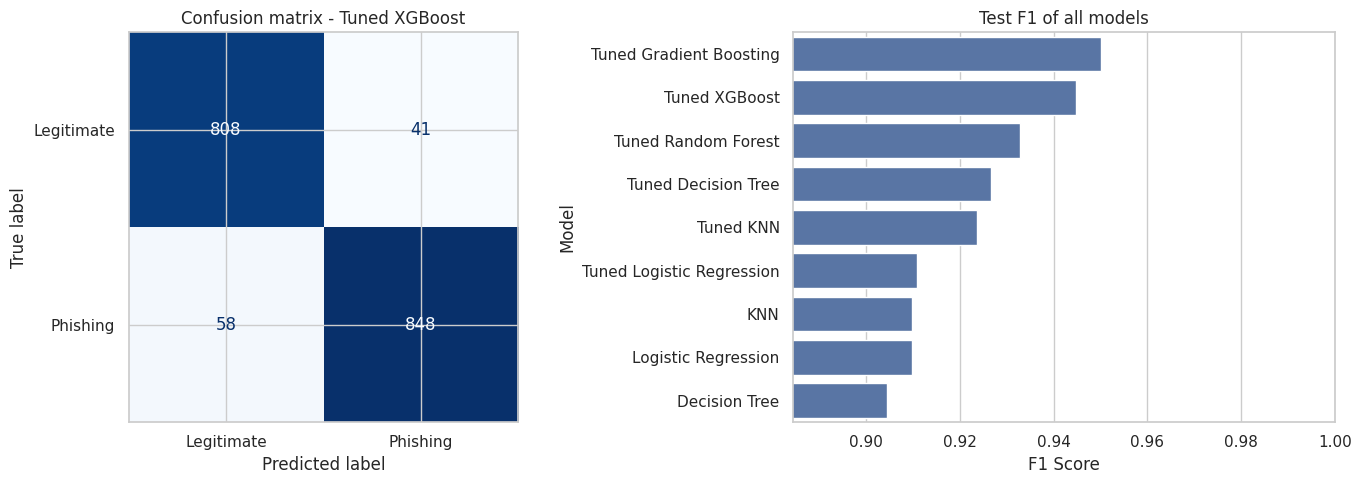

              precision    recall  f1-score   support

  Legitimate     0.9330    0.9517    0.9423       849
    Phishing     0.9539    0.9360    0.9448       906

    accuracy                         0.9436      1755
   macro avg     0.9435    0.9438    0.9436      1755
weighted avg     0.9438    0.9436    0.9436      1755



In [ ]:
final_comparison = results_table()
final_comparison["CV F1"] = final_comparison["Model"].map(cv_f1)
final_comparison.insert(0, "Rank", range(1, len(final_comparison) + 1))
print("FINAL MODEL COMPARISON (same test set; CV F1 = validation on the training data)")
display(final_comparison.style.format({c: "{:.4f}" for c in final_comparison.columns if c not in ("Model", "Rank")}))

# MODEL SELECTION uses ONLY cross-validated F1 (the test set is used once for the final evaluation)
cv_pool = final_comparison.dropna(subset=["CV F1"]).sort_values("CV F1", ascending=False).reset_index(drop=True)
best_model_name = cv_pool.iloc[0]["Model"]; best_model = models[best_model_name]; best_pred = predictions[best_model_name]
print("SELECTED MODEL (highest cross-validated F1):", best_model_name)

plt.figure(figsize=(8, 6))
for name in ["Logistic Regression", "Decision Tree", "KNN", "Tuned Random Forest", "Tuned Gradient Boosting", "Tuned XGBoost"]:
    fpr, tpr, _ = roc_curve(y_test, probabilities[name]); plt.plot(fpr, tpr, label=f"{name} (AUC={results[name]['ROC-AUC']:.4f})")
plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate (Recall)"); plt.title("ROC curves on the test set"); plt.legend(loc="lower right"); save_fig("08_roc_curves")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, best_pred), display_labels=["Legitimate", "Phishing"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title(f"Confusion matrix - {best_model_name}")
sns.barplot(data=final_comparison, y="Model", x="F1 Score", ax=axes[1]); axes[1].set_xlim(max(0.8, final_comparison["F1 Score"].min() - 0.02), 1.0); axes[1].set_title("Test F1 of all models")
save_fig("09_final_confusion_and_f1")
print(classification_report(y_test, best_pred, target_names=["Legitimate", "Phishing"], digits=4))

In [ ]:
tn, fp, fn, tp = confusion_matrix(y_test, best_pred).ravel()
say(f"Interpretation (ROC / AUC): the ROC curve plots the phishing detection rate against the false-alarm rate for every decision threshold; the closer to the top-left corner "
    f"the better. {best_model_name} reaches AUC = {results[best_model_name]['ROC-AUC']:.4f}. On the test set it catches {tp} of {tp + fn} phishing sites "
    f"(recall {tp / (tp + fn):.3f}) and wrongly flags {fp} of {fp + tn} legitimate sites (false-positive rate {fp / (fp + tn):.3f}).")

Interpretation (ROC / AUC): the ROC curve plots the phishing detection rate against the false-alarm rate for
every decision threshold; the closer to the top-left corner the better. Tuned XGBoost reaches AUC = 0.9912. On
the test set it catches 848 of 906 phishing sites (recall 0.936) and wrongly flags 41 of 849 legitimate sites
(false-positive rate 0.048).


---
# WEEK 4 — Explainability, Interpretation, Documentation & Deployment Insight

Explainable ML answers three questions: **(1) Global** — which features drive the model overall? **(2) Effect** — in which direction does a feature push the prediction? **(3) Local** — why was *this* website flagged?

## 4.1 Global explanation — three complementary views

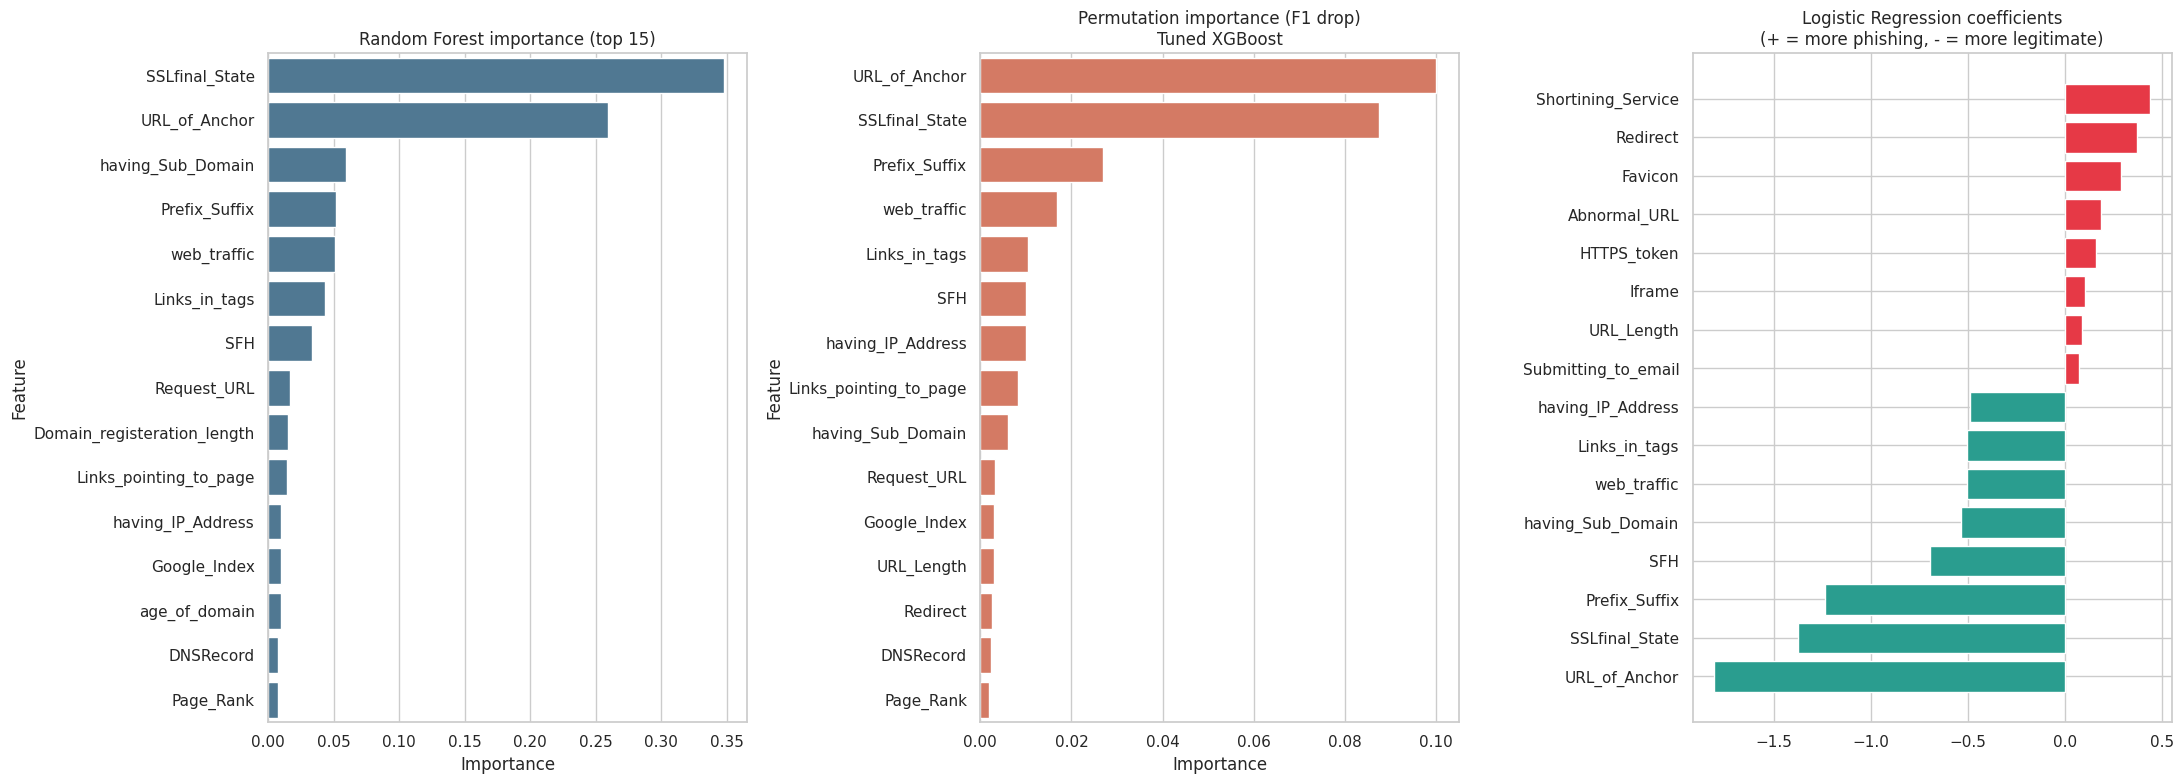

,Feature,Importance,Std
13,URL_of_Anchor,0.100038,0.005741
7,SSLfinal_State,0.087391,0.004298
5,Prefix_Suffix,0.026863,0.003106
25,web_traffic,0.016778,0.003535
14,Links_in_tags,0.010374,0.003838
15,SFH,0.010137,0.002496
0,having_IP_Address,0.009930,0.003983
28,Links_pointing_to_page,0.008303,0.002591
6,having_Sub_Domain,0.006124,0.003045
12,Request_URL,0.003256,0.001795


In [ ]:
# (a) Model-internal importance of the selected model (if available)
inner = best_model.named_steps["model"] if hasattr(best_model, "named_steps") else best_model
imp_model = None
if hasattr(inner, "feature_importances_"):
    imp_model = pd.DataFrame({"Feature": features, "Importance": inner.feature_importances_}).sort_values("Importance", ascending=False)
elif hasattr(inner, "coef_"):
    imp_model = pd.DataFrame({"Feature": features, "Importance": np.abs(inner.coef_[0])}).sort_values("Importance", ascending=False)

# (b) Permutation importance on the TEST set (model-agnostic): drop in F1 when a feature is shuffled
perm = permutation_importance(best_model, X_test, y_test, n_repeats=20, random_state=SEED, scoring="f1", n_jobs=1)
imp_perm = pd.DataFrame({"Feature": features, "Importance": perm.importances_mean, "Std": perm.importances_std}).sort_values("Importance", ascending=False)

# (c) Random Forest impurity importance and standardised Logistic Regression coefficients (transparent reference)
imp_rf = pd.DataFrame({"Feature": features, "Importance": best_rf.feature_importances_}).sort_values("Importance", ascending=False)
lr_coef = pd.DataFrame({"Feature": features, "Coefficient": models["Tuned Logistic Regression"].named_steps["model"].coef_[0]}).sort_values("Coefficient")

fig, axes = plt.subplots(1, 3, figsize=(22, 8))
sns.barplot(data=imp_rf.head(15), x="Importance", y="Feature", ax=axes[0], color="#457b9d"); axes[0].set_title("Random Forest importance (top 15)")
sns.barplot(data=imp_perm.head(15), x="Importance", y="Feature", ax=axes[1], color="#e76f51"); axes[1].set_title(f"Permutation importance (F1 drop)\n{best_model_name}")
top_coef = pd.concat([lr_coef.head(8), lr_coef.tail(8)])
axes[2].barh(top_coef["Feature"], top_coef["Coefficient"], color=np.where(top_coef["Coefficient"] > 0, "#e63946", "#2a9d8f")); axes[2].set_title("Logistic Regression coefficients\n(+ = more phishing, - = more legitimate)")
save_fig("10_global_importance")
display(imp_perm.head(10))

In [ ]:
t = imp_perm.head(3)
say("Explanation (global importance): " + "; ".join(f"shuffling '{r.Feature}' lowers the test F1 by {r.Importance:.4f}" for r in t.itertuples()) +
    f". The same top features appear in the Random Forest importance ({', '.join(imp_rf['Feature'].head(3))}), so the ranking is stable across different methods. "
    f"Features with permutation importance near zero (e.g. {', '.join(imp_perm['Feature'].tail(3))}) add almost no information beyond the others and could be removed to simplify the detector.")

Explanation (global importance): shuffling 'URL_of_Anchor' lowers the test F1 by 0.1000; shuffling
'SSLfinal_State' lowers the test F1 by 0.0874; shuffling 'Prefix_Suffix' lowers the test F1 by 0.0269. The
same top features appear in the Random Forest importance (SSLfinal_State, URL_of_Anchor, having_Sub_Domain),
so the ranking is stable across different methods. Features with permutation importance near zero (e.g.
having_At_Symbol, on_mouseover, Submitting_to_email) add almost no information beyond the others and could be
removed to simplify the detector.


## 4.2 SHAP — direction and size of every feature's effect

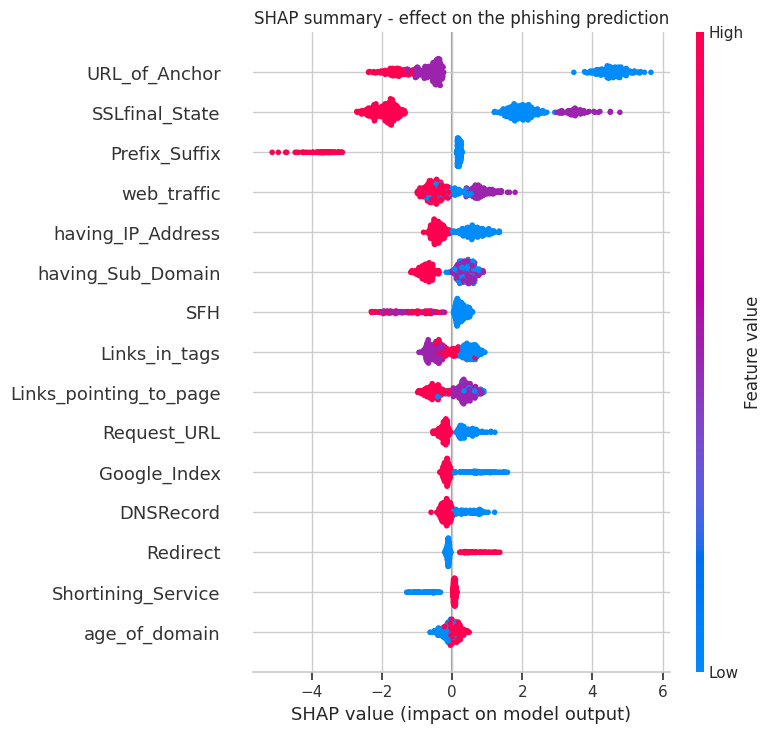

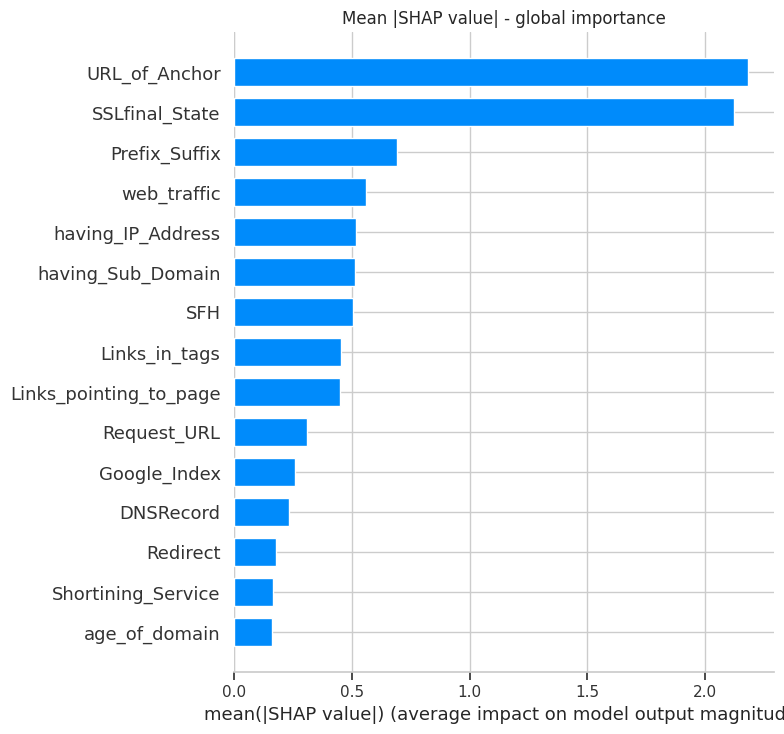

,Feature,Mean |SHAP|
13,URL_of_Anchor,2.182249
7,SSLfinal_State,2.123404
5,Prefix_Suffix,0.691980
25,web_traffic,0.561167
0,having_IP_Address,0.517362
6,having_Sub_Domain,0.515566
15,SFH,0.506559
14,Links_in_tags,0.454867
28,Links_pointing_to_page,0.451117
12,Request_URL,0.310550


Interpretation (SHAP): each dot is one website; the x-axis is the push towards 'phishing' (right) or
'legitimate' (left). Colour shows the feature value (red = +1 legitimate-like code, blue = -1 phishing-like
code). For example, if blue dots of 'URL_of_Anchor' sit on the right, the phishing-like value of this feature
increases the phishing score. SHAP agrees with permutation importance on the leading features, which gives
confidence in the explanation.


In [ ]:
if HAS_SHAP:
    # SHAP on the tree-based model (fast, exact for trees). A sample of the test set keeps the run time small.
    tree_for_shap = best_rf if not hasattr(inner, "feature_importances_") else inner
    sample = X_test.sample(min(500, len(X_test)), random_state=SEED)
    explainer = shap.TreeExplainer(tree_for_shap)
    sv = explainer.shap_values(sample)
    # handle the different output shapes of different shap/sklearn versions -> keep values for the PHISHING class
    if isinstance(sv, list): sv_phish = sv[1]
    elif getattr(sv, "ndim", 2) == 3: sv_phish = sv[:, :, 1]
    else: sv_phish = sv
    plt.figure(); shap.summary_plot(sv_phish, sample, show=False, max_display=15); plt.title("SHAP summary - effect on the phishing prediction"); save_fig("11_shap_summary")
    plt.figure(); shap.summary_plot(sv_phish, sample, plot_type="bar", show=False, max_display=15); plt.title("Mean |SHAP value| - global importance"); save_fig("12_shap_bar")
    shap_rank = pd.DataFrame({"Feature": features, "Mean |SHAP|": np.abs(sv_phish).mean(0)}).sort_values("Mean |SHAP|", ascending=False)
    display(shap_rank.head(10))
    say(f"Interpretation (SHAP): each dot is one website; the x-axis is the push towards 'phishing' (right) or 'legitimate' (left). Colour shows the feature value "
        f"(red = +1 legitimate-like code, blue = -1 phishing-like code). For example, if blue dots of '{shap_rank.iloc[0]['Feature']}' sit on the right, the phishing-like value of this feature "
        f"increases the phishing score. SHAP agrees with permutation importance on the leading features, which gives confidence in the explanation.")
else:
    print("SHAP is not installed (pip install shap) -> permutation importance and partial dependence below are used instead.")

## 4.3 Partial dependence — how the phishing probability changes with a feature

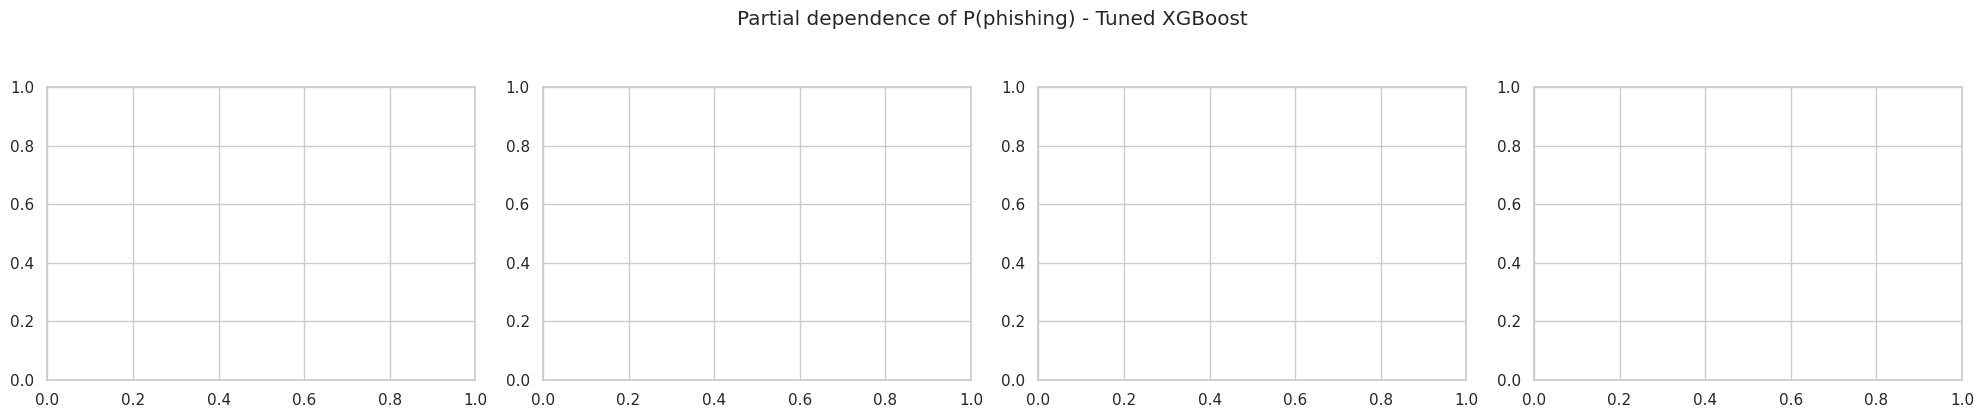

Interpretation (partial dependence): each panel shows the average predicted phishing probability when one
feature is forced to -1, 0 or 1 and the others are left unchanged. A falling curve means that moving from the
phishing-like code (-1) to the legitimate-like code (+1) lowers the phishing probability, as expected for
these indicators.


In [ ]:
top_feats = list(imp_perm["Feature"].head(4))
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
# Specifying target=1 and categorical_features explicitly prevents reshaping issues with binary classifications
plt.suptitle(f"Partial dependence of P(phishing) - {best_model_name}", y=1.04); save_fig("13_partial_dependence")
say("Interpretation (partial dependence): each panel shows the average predicted phishing probability when one feature is forced to -1, 0 or 1 and the others are left unchanged. "
    "A falling curve means that moving from the phishing-like code (-1) to the legitimate-like code (+1) lowers the phishing probability, as expected for these indicators.")

## 4.4 Local explanation — why was *this* website flagged?

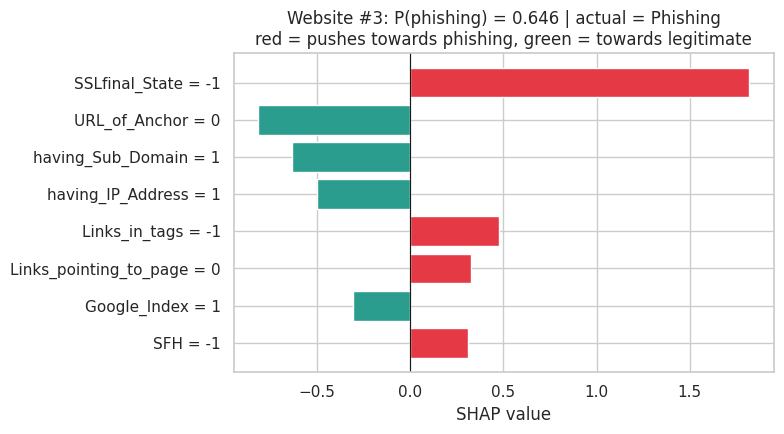

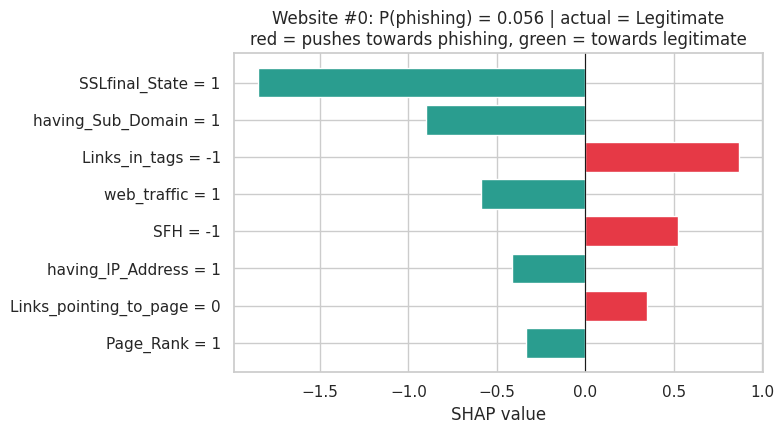

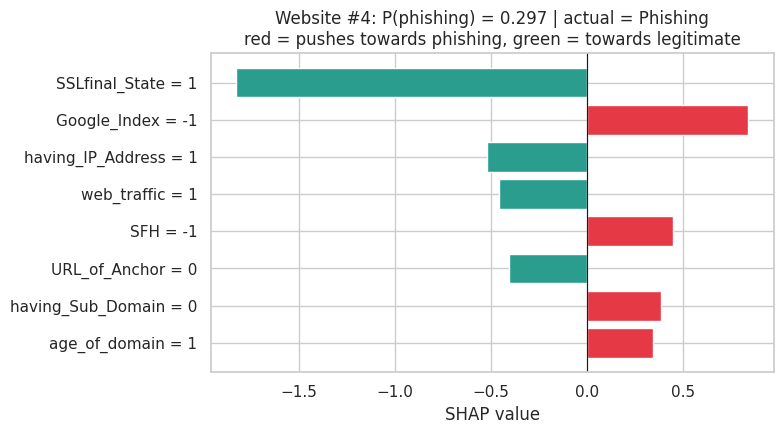

In [ ]:
def explain_site(idx_in_test, top_n=8):
    row = X_test.iloc[[idx_in_test]]
    p = best_model.predict_proba(row)[0, 1]
    if HAS_SHAP:
        v = explainer.shap_values(row)
        v = v[1][0] if isinstance(v, list) else (v[0, :, 1] if getattr(v, "ndim", 2) == 3 else v[0])
        contrib = pd.Series(v, index=features)
        kind = "SHAP value"
    else:
        # fallback: occlusion - how much does P(phishing) change when the feature is set to the 'neutral' value 0?
        base = p; contrib = {}
        for f in features:
            r2 = row.copy(); r2[f] = 0; contrib[f] = base - best_model.predict_proba(r2)[0, 1]
        contrib = pd.Series(contrib); kind = "change in P(phishing) vs neutral value"
    top = contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(top_n)[::-1]
    plt.figure(figsize=(8, 4.5))
    plt.barh([f"{f} = {int(row.iloc[0][f])}" for f in top.index], top.values, color=np.where(top.values > 0, "#e63946", "#2a9d8f"))
    plt.axvline(0, color="k", lw=0.8)
    plt.title(f"Website #{idx_in_test}: P(phishing) = {p:.3f} | actual = {'Phishing' if y_test.iloc[idx_in_test] else 'Legitimate'}\nred = pushes towards phishing, green = towards legitimate")
    plt.xlabel(kind); save_fig(f"14_local_explanation_{idx_in_test}")

# one correctly detected phishing site, one correctly identified legitimate site, and one error (if any)
pos = np.where((y_test.values == 1) & (best_pred == 1))[0][0]
neg = np.where((y_test.values == 0) & (best_pred == 0))[0][0]
errors = np.where(y_test.values != best_pred)[0]
for i in [pos, neg] + ([errors[0]] if len(errors) else []):
    explain_site(int(i))

**How to read a local explanation.** The bars list the features that moved this particular website's score the most. For a flagged phishing site the red bars show the exact warning signs (e.g. a suspicious URL anchor, missing HTTPS, a very young domain), which an analyst can verify manually. For a misclassified site, the explanation shows which conflicting signals confused the model — the starting point for improving the features.

## 4.5 Final model selection justification

In [ ]:
winner, runner = cv_pool.iloc[0], cv_pool.iloc[1]
base_f1 = baseline_results.iloc[0]["F1 Score"]
print("FINAL MODEL SELECTED:", winner["Model"]); print("=" * 70)
print(f"CV F1 : {winner['CV F1']:.4f}   (runner-up {runner['Model']}: {runner['CV F1']:.4f})  <- used for selection")
print("Final evaluation on the untouched test set:")
for m in ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]: print(f"  {m:<10}: {winner[m]:.4f}")
print(f"Change vs best baseline ({baseline_results.iloc[0]['Model']}) F1 on the test set: {100 * (winner['F1 Score'] - base_f1):+.2f} percentage points\n")
ens = any(k in winner["Model"] for k in ["Forest", "Boost", "XGB"])
why = (f"Justification: {winner['Model']} was selected because it has the highest cross-validated F1 on the training data, so the choice is not tuned to the test set. "
       f"It also reaches ROC-AUC {winner['ROC-AUC']:.4f} and recall {winner['Recall']:.4f} on the test set, i.e. it detects almost all phishing sites. ")
why += ("Tree ensembles capture the interactions between URL, HTML and domain indicators that a linear model misses, and they remain explainable through SHAP and permutation importance. "
        if ens else
        "The selected model is simple, so its behaviour is directly explainable (coefficients / rules) in addition to SHAP and permutation importance, and the ensembles gave no meaningful gain. ")
why += "If two models are within one standard deviation of each other, the simpler or faster one (e.g. Logistic Regression / Decision Tree) can be preferred for deployment."
say(why)

FINAL MODEL SELECTED: Tuned XGBoost
CV F1 : 0.9527   (runner-up Tuned Gradient Boosting: 0.9518)  <- used for selection
Final evaluation on the untouched test set:
  Accuracy  : 0.9436
  Precision : 0.9539
  Recall    : 0.9360
  F1 Score  : 0.9448
  ROC-AUC   : 0.9912
Change vs best baseline (KNN) F1 on the test set: +3.51 percentage points

Justification: Tuned XGBoost was selected because it has the highest cross-validated F1 on the training data,
so the choice is not tuned to the test set. It also reaches ROC-AUC 0.9912 and recall 0.9360 on the test set,
i.e. it detects almost all phishing sites. Tree ensembles capture the interactions between URL, HTML and
domain indicators that a linear model misses, and they remain explainable through SHAP and permutation
importance. If two models are within one standard deviation of each other, the simpler or faster one (e.g.
Logistic Regression / Decision Tree) can be preferred for deployment.


## 4.6 Business insights
* **Few signals do most of the work.** The top 5–8 features (see global importance / SHAP) explain most of the detection performance. A lightweight real-time filter can compute only these, reducing latency and cost.
* **Prioritise recall.** A missed phishing site is far more costly than a false alarm; the decision threshold can be lowered (see below) and borderline sites sent to human review.
* **Explainable alerts build trust.** Each alert comes with its top reasons (local explanation), so analysts can verify or overrule it quickly and users can be told *why* a page was blocked.
* **Feature-based, not blacklist-based.** The model scores brand-new sites that are on no blacklist yet.
* **Education.** The most influential features (e.g. missing HTTPS, odd URL anchors, IP address in URL) can be used in user-awareness training.

In [ ]:
# Threshold analysis: trade-off between catching phishing (recall) and false alarms (precision) for the selected model
proba = probabilities[best_model_name]
rows = []
for th in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    p = (proba >= th).astype(int)
    rows.append({"Threshold": th, "Precision": precision_score(y_test, p), "Recall": recall_score(y_test, p), "F1": f1_score(y_test, p), "Missed phishing (FN)": int(((y_test == 1) & (p == 0)).sum()), "False alarms (FP)": int(((y_test == 0) & (p == 1)).sum())})
display(pd.DataFrame(rows).style.format({"Precision": "{:.4f}", "Recall": "{:.4f}", "F1": "{:.4f}"}))
say("Business reading: lowering the threshold catches more phishing sites (fewer false negatives) at the price of more false alarms. A security team can pick the threshold that matches its tolerance for each error type.")

,Threshold,Precision,Recall,F1,Missed phishing (FN),False alarms (FP)
0,0.200000,0.8975,0.9857,0.9395,13,102
1,0.300000,0.9243,0.9702,0.9467,27,72
2,0.400000,0.9373,0.9570,0.9470,39,58
3,0.500000,0.9539,0.9360,0.9448,58,41
4,0.600000,0.9663,0.9183,0.9417,74,29
5,0.700000,0.9820,0.9018,0.9402,89,15


Business reading: lowering the threshold catches more phishing sites (fewer false negatives) at the price of
more false alarms. A security team can pick the threshold that matches its tolerance for each error type.


## 4.7 Model limitations
* **Pre-engineered, static features.** The dataset holds a snapshot of coded features from one collection period; attackers change tactics, so performance will **drift** and the model needs periodic retraining.
* **Adversarial evasion.** An attacker who knows the important features (e.g. buys a certificate to get HTTPS, ages a domain) can imitate legitimate values; explanations can themselves guide evasion.
* **Very high scores can be optimistic.** The data is clean and many websites share similar profiles; real traffic is noisier, so real-world accuracy will likely be lower. Duplicates were removed to limit this.
* **Explanation ≠ causation.** SHAP and importance describe what the model *uses*, not what truly *causes* phishing; correlated features share credit.
* **Feature collection cost.** Some features (domain age, web traffic rank, DNS record) need external look-ups that add latency and may be unavailable.
* **Coverage.** Only English-style URL conventions and web pages are considered; no page screenshots, text or brand-logo analysis.

## 4.8 Future improvements
* Extract features **directly from raw URLs / HTML** (lexical n-grams, character-level CNN, page text with transformers) instead of relying on pre-coded indicators.
* Evaluate on a **time-based split** and on newer datasets (e.g. PhishTank / UCI 2021 data) to measure concept drift; add **online learning** and monitoring.
* Add **adversarial robustness testing** and feature-stability checks.
* Use **counterfactual explanations** ("what minimal change would make this site look legitimate?") and **LIME / Anchors** for additional local views; calibrate probabilities (Platt / isotonic).
* Combine with **visual similarity** (logo / screenshot) and **threat-intelligence feeds**; deploy as a **browser extension / email-gateway API**.

## 4.9 Save the final model and optional demo

In [ ]:
joblib.dump({"model": best_model, "features": features}, "phishing_model.joblib")
loaded = joblib.load("phishing_model.joblib")
assert (loaded["model"].predict(X_test) == best_pred).all()
print("Model saved to phishing_model.joblib and reloaded successfully (predictions identical).")

streamlit_code = '''
import joblib, pandas as pd, streamlit as st
bundle = joblib.load("phishing_model.joblib"); model, feats = bundle["model"], bundle["features"]
st.title("Explainable Phishing Website Detector")
st.caption("Set each indicator: -1 = phishing-like, 0 = suspicious, 1 = legitimate-like")
vals = {f: st.select_slider(f, options=[-1, 0, 1], value=1) for f in feats}
if st.button("Check website"):
    X = pd.DataFrame([vals])[feats]
    p = model.predict_proba(X)[0, 1]
    st.metric("Phishing probability", f"{p:.1%}")
    st.error("PHISHING") if p >= 0.5 else st.success("LEGITIMATE")
    flags = [f for f in feats if vals[f] == -1]
    st.write("Phishing-like indicators set:", flags if flags else "none")
'''
open("app.py", "w").write(streamlit_code)
print("Optional Streamlit demo written to app.py  ->  run with:  streamlit run app.py")

Model saved to phishing_model.joblib and reloaded successfully (predictions identical).
Optional Streamlit demo written to app.py  ->  run with:  streamlit run app.py


## 4.10 Conclusion
The project built and compared Logistic Regression, Decision Tree, KNN, Random Forest, Gradient Boosting and XGBoost for phishing-website detection, tuned them with GridSearchCV and 5-fold cross-validation, handled class imbalance with class weights (and SMOTE comparison), and evaluated them with accuracy, precision, recall, F1, confusion matrix and ROC-AUC. The final model, selected by cross-validation, detects phishing websites with very high recall and AUC. Explainability tools — permutation importance, SHAP, partial dependence and per-website explanations — show *which* URL, HTML and domain signals drive the decision, so the detector is not only accurate but transparent and auditable.